# KhmerIR: Khmer Tokenization, Lexical, Dense & Hybrid Retrieval Benchmark

**Local research notebook** — compares Khmer text processing and retrieval methods with a reproducible workflow. It runs end to end on the local `.venv` kernel (Python 3.14). Every section executes; there are no optional switches.

## What this notebook tests

1. **Khmer text preparation:** Unicode normalization, whitespace cleanup, raw text vs word-segmented text.
2. **Khmer word segmentation:** `khmer-nltk` (CRF word segmenter) compared against a whitespace-only baseline.
3. **Segmentation evaluation:** boundary precision / recall / F1 against a small hand-annotated gold set.
4. **Lexical retrieval:** TF-IDF and BM25 on normalized vs segmented text.
5. **Dense retrieval:** EmbeddingGemma 2 and Qwen3-VL-Embedding-2B (official SentenceTransformers interface and prompts).
6. **Hybrid retrieval:** reciprocal-rank fusion (RRF) of lexical and dense results.
7. **Multimodal retrieval:** text→image and image→text on the local `media.csv` images.
8. **Evaluation:** Recall@K, Precision@K, MRR, nDCG, latency, vector storage, Matryoshka dimensions.
9. **Visual analysis:** plots for retrieval quality, segmenter comparison, latency, storage, and per-query errors.

> **Research caution:** the built-in corpus is a smoke test, not a benchmark. Published scores from different datasets or evaluation conventions are not directly comparable. Use the same query–document relevance judgments for every retrieval experiment.

## 0. Runtime and reproducibility

Kernel: **`.venv (3.14.10)`** at the workspace root. All packages are already installed there; the next cell only *checks* them (no `pip install`, no Colab).

- Working directory = the folder containing this notebook (`Project/experiments`). `media.csv` and `image*.jpg` are read from here; results are written to `./khmerir_results/`.
- Dense models load from the local Hugging Face cache (`~/.cache/huggingface`). They are loaded **one at a time** and freed afterwards so both fit on a laptop (4 GB GPU / 16 GB RAM).
- If `docs.csv` and `queries.csv` exist next to the notebook they replace the demo corpus automatically.

In [28]:
# Dependency check for the local .venv kernel (nothing is installed here).
import importlib, sys

REQUIRED = {
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
    "matplotlib": "matplotlib", "seaborn": "seaborn", "rank_bm25": "rank-bm25", "tqdm": "tqdm",
    "psutil": "psutil", "PIL": "pillow", "torch": "torch", "transformers": "transformers",
    "sentence_transformers": "sentence-transformers", "huggingface_hub": "huggingface_hub",
    "khmernltk": "khmer-nltk",
}
missing = []
for module, pip_name in REQUIRED.items():
    try:
        importlib.import_module(module)
    except Exception as e:
        missing.append((pip_name, repr(e)))

print("Kernel interpreter:", sys.executable)
if missing:
    raise ImportError("Missing packages in this kernel — install with "
                      f"`{sys.executable} -m pip install " + " ".join(p for p, _ in missing) + "`\n"
                      + "\n".join(f"  {p}: {err}" for p, err in missing))
print("All", len(REQUIRED), "required packages are importable.")

Kernel interpreter: /home/hour/Documents/CADT/Y4 T1/Information Web Retrieval/.venv/bin/python
All 15 required packages are importable.


In [29]:
import os, re, json, time, math, random, warnings, gc, platform, unicodedata
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import torch
from PIL import Image

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

BASE_DIR = Path.cwd()
RESULTS_DIR = BASE_DIR / "khmerir_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
TOP_K = 5

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Working directory:", BASE_DIR)
print("RAM: %.1f GiB total, %.1f GiB available" % (psutil.virtual_memory().total / 2**30,
                                                   psutil.virtual_memory().available / 2**30))
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), "| VRAM free %.2f / %.2f GiB" % (free / 2**30, total / 2**30))

Python: 3.14.10
Platform: Linux-7.2.3-arch1-2-x86_64-with-glibc2.44
Working directory: /home/hour/Documents/CADT/Y4 T1/Information Web Retrieval/Project/experiments
RAM: 15.0 GiB total, 5.1 GiB available
PyTorch: 2.15.0+cu132 | CUDA available: True
GPU: NVIDIA GeForce GTX 1650 | VRAM free 3.56 / 3.64 GiB


## 1. Load the corpus and evaluation queries

### Expected CSV formats

**Documents CSV** (`docs.csv`): `doc_id`, `text` (Khmer, English, or mixed)

**Queries CSV** (`queries.csv`): `query_id`, `query`, `relevant_doc_ids` (relevant IDs separated by `;`, e.g. `D001;D004`)

If both files are next to this notebook they are used; otherwise the built-in demo corpus below is used. Keep relevance labels independent from the systems being evaluated.

In [30]:
# Small illustrative corpus. Replace with your own annotated data (docs.csv / queries.csv) for research conclusions.
demo_docs = [
    ("D001", "ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។ Angkor Wat is a famous temple in Cambodia."),
    ("D002", "ការសិក្សាបញ្ញាសិប្បនិម្មិត ពាក់ព័ន្ធនឹង machine learning និង deep learning។"),
    ("D003", "បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។"),
    ("D004", "អង្គការសហប្រជាជាតិ (United Nations) មានតួនាទីក្នុងកិច្ចសហប្រតិបត្តិការអន្តរជាតិ។"),
    ("D005", "Khmer natural language processing includes word segmentation, tokenization, information retrieval and text classification."),
    ("D006", "ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។ Phnom Penh is the capital of Cambodia."),
    ("D007", "បច្ចេកវិទ្យាកុំព្យូទ័រ និងបណ្ដាញអ៊ីនធឺណិតជួយដល់ការអប់រំ។"),
    ("D008", "A document about Cambodian traditional wooden houses, architecture, roofs, columns and construction materials."),
    ("D009", "រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។"),
    ("D010", "BM25 and TF-IDF are lexical information retrieval methods; dense embeddings represent semantic relationships."),
]
demo_queries = [
    ("Q001", "ប្រាសាទអង្គរវត្តនៅឯណា?", "D001"),
    ("Q002", "Khmer word segmentation and information retrieval", "D005"),
    ("Q003", "តើរាជធានីកម្ពុជាឈ្មោះអ្វី?", "D006"),
    ("Q004", "United Nations", "D004"),
    ("Q005", "traditional Cambodian wooden house", "D008;D009"),
    ("Q006", "វិធីសាស្ត្រស្វែងរកឯកសារតាមន័យ", "D002;D005;D010"),
    ("Q007", "ទន្លេសាប", "D003"),
]

docs_csv, queries_csv = BASE_DIR / "docs.csv", BASE_DIR / "queries.csv"
if docs_csv.exists() and queries_csv.exists():
    docs = pd.read_csv(docs_csv).fillna("")
    queries = pd.read_csv(queries_csv).fillna("")
    assert {"doc_id", "text"}.issubset(docs.columns), "docs.csv needs doc_id, text"
    assert {"query_id", "query", "relevant_doc_ids"}.issubset(queries.columns), \
        "queries.csv needs query_id, query, relevant_doc_ids"
    DATA_SOURCE = "local CSV files"
else:
    docs = pd.DataFrame(demo_docs, columns=["doc_id", "text"])
    queries = pd.DataFrame(demo_queries, columns=["query_id", "query", "relevant_doc_ids"])
    DATA_SOURCE = "built-in demo corpus"

docs["doc_id"] = docs["doc_id"].astype(str)
queries["query_id"] = queries["query_id"].astype(str)
queries["relevant_doc_ids"] = queries["relevant_doc_ids"].astype(str)
queries = queries.reset_index(drop=True)
docs = docs.reset_index(drop=True)

print("Data source:", DATA_SOURCE)
print("Documents:", len(docs), "| Queries:", len(queries))
display(docs)
display(queries)

Data source: built-in demo corpus
Documents: 10 | Queries: 7


,doc_id,text
0,D001,ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។ Angkor Wat is a famous temple in Cambodia.
1,D002,ការសិក្សាបញ្ញាសិប្បនិម្មិត ពាក់ព័ន្ធនឹង machine learning និង deep learning។
2,D003,បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។
3,D004,អង្គការសហប្រជាជាតិ (United Nations) មានតួនាទីក្នុងកិច្ចសហប្រតិបត្តិការអន្តរជាតិ។
4,D005,"Khmer natural language processing includes word segmentation, tokenization, information retrieval and text classific..."
5,D006,ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។ Phnom Penh is the capital of Cambodia.
6,D007,បច្ចេកវិទ្យាកុំព្យូទ័រ និងបណ្ដាញអ៊ីនធឺណិតជួយដល់ការអប់រំ។
7,D008,"A document about Cambodian traditional wooden houses, architecture, roofs, columns and construction materials."
8,D009,រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។
9,D010,BM25 and TF-IDF are lexical information retrieval methods; dense embeddings represent semantic relationships.


,query_id,query,relevant_doc_ids
0,Q001,ប្រាសាទអង្គរវត្តនៅឯណា?,D001
1,Q002,Khmer word segmentation and information retrieval,D005
2,Q003,តើរាជធានីកម្ពុជាឈ្មោះអ្វី?,D006
3,Q004,United Nations,D004
4,Q005,traditional Cambodian wooden house,D008;D009
5,Q006,វិធីសាស្ត្រស្វែងរកឯកសារតាមន័យ,D002;D005;D010
6,Q007,ទន្លេសាប,D003


## 2. Khmer normalization and segmentation

Khmer does not reliably mark word boundaries with spaces. A segmenter predicts word boundaries; a Transformer tokenizer then maps text into the model's own subword vocabulary. These are distinct operations.

The notebook keeps several text variants:
- `text`: original text
- `normalized`: Unicode NFC, zero-width characters removed, whitespace collapsed
- `segmented_whitespace`: whitespace-only baseline (**not** a Khmer word segmenter)
- `segmented`: output of the `khmer-nltk` word segmenter, tokens joined by single spaces

In [31]:
ZERO_WIDTH = dict.fromkeys(map(ord, "​‌‍﻿"), None)

def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text)).translate(ZERO_WIDTH)
    text = re.sub(r"\s+", " ", text)   # tabs, newlines and repeated spaces -> one space
    return text.strip()

assert normalize_text("Khmer  natural\tlanguage\nprocessing​") == "Khmer natural language processing"

docs["normalized"] = docs["text"].map(normalize_text)
queries["normalized"] = queries["query"].map(normalize_text)
display(docs[["doc_id", "text", "normalized"]])

,doc_id,text,normalized
0,D001,ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។ Angkor Wat is a famous temple in Cambodia.,ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។ Angkor Wat is a famous temple in Cambodia.
1,D002,ការសិក្សាបញ្ញាសិប្បនិម្មិត ពាក់ព័ន្ធនឹង machine learning និង deep learning។,ការសិក្សាបញ្ញាសិប្បនិម្មិត ពាក់ព័ន្ធនឹង machine learning និង deep learning។
2,D003,បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។,បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។
3,D004,អង្គការសហប្រជាជាតិ (United Nations) មានតួនាទីក្នុងកិច្ចសហប្រតិបត្តិការអន្តរជាតិ។,អង្គការសហប្រជាជាតិ (United Nations) មានតួនាទីក្នុងកិច្ចសហប្រតិបត្តិការអន្តរជាតិ។
4,D005,"Khmer natural language processing includes word segmentation, tokenization, information retrieval and text classific...","Khmer natural language processing includes word segmentation, tokenization, information retrieval and text classific..."
5,D006,ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។ Phnom Penh is the capital of Cambodia.,ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។ Phnom Penh is the capital of Cambodia.
6,D007,បច្ចេកវិទ្យាកុំព្យូទ័រ និងបណ្ដាញអ៊ីនធឺណិតជួយដល់ការអប់រំ។,បច្ចេកវិទ្យាកុំព្យូទ័រ និងបណ្ដាញអ៊ីនធឺណិតជួយដល់ការអប់រំ។
7,D008,"A document about Cambodian traditional wooden houses, architecture, roofs, columns and construction materials.","A document about Cambodian traditional wooden houses, architecture, roofs, columns and construction materials."
8,D009,រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។,រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។
9,D010,BM25 and TF-IDF are lexical information retrieval methods; dense embeddings represent semantic relationships.,BM25 and TF-IDF are lexical information retrieval methods; dense embeddings represent semantic relationships.


### 2A. Segmenters

- **whitespace** — baseline only; splits on spaces already present.
- **khmer-nltk** — CRF-based Khmer word segmenter (`khmernltk.word_tokenize`). Its whitespace tokens are dropped so the output is space-delimited words.

The `khmernlp` package is not used: it needs TensorFlow, which has no build for this Python 3.14 environment. UnifiedCut / KhPOS can be added later as another entry in `SEGMENTERS`.

In [32]:
from khmernltk import word_tokenize as khmernltk_word_tokenize
import logging
logging.getLogger("khmer-nltk").setLevel(logging.WARNING)

def whitespace_segment(text):
    # Not true Khmer word segmentation; only splits on spaces already present.
    return " ".join(normalize_text(text).split())

def khmernltk_segment(text):
    tokens = khmernltk_word_tokenize(normalize_text(text))
    return " ".join(t.strip() for t in tokens if t.strip())

SEGMENTERS = {"whitespace": whitespace_segment, "khmer-nltk": khmernltk_segment}
PRIMARY_SEGMENTER = "khmer-nltk"
segmenter_fn = SEGMENTERS[PRIMARY_SEGMENTER]

docs["segmented_whitespace"] = docs["normalized"].map(whitespace_segment)
queries["segmented_whitespace"] = queries["normalized"].map(whitespace_segment)
docs["segmented"] = docs["normalized"].map(segmenter_fn)
queries["segmented"] = queries["normalized"].map(segmenter_fn)

print("Primary segmenter:", PRIMARY_SEGMENTER)
pd.set_option("display.max_colwidth", 120)
display(docs[["doc_id", "normalized", "segmented"]])
display(queries[["query_id", "normalized", "segmented"]])

Primary segmenter: khmer-nltk


,doc_id,normalized,segmented
0,D001,ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។ Angkor Wat is a famous temple in Cambodia.,ប្រាសាទ អង្គរវត្ត គឺជា ប្រាសាទ ហិណ្ឌូ ដ៏ ធំ មួយ នៅ ខេត្ត សៀមរាប ។ Angkor Wat is a famous temple in Cambodia .
1,D002,ការសិក្សាបញ្ញាសិប្បនិម្មិត ពាក់ព័ន្ធនឹង machine learning និង deep learning។,ការសិក្សា បញ្ញា សិប្បនិម្មិត ពាក់ព័ន្ធ នឹង machine learning និង deep learning ។
2,D003,បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។,បឹង ទន្លេ សាប ជា បឹង ទឹក សាប ដ៏ ធំ នៅ កម្ពុជា និង មាន សារៈសំខាន់ ចំពោះ ជីវភាព ប្រជាជន ។
3,D004,អង្គការសហប្រជាជាតិ (United Nations) មានតួនាទីក្នុងកិច្ចសហប្រតិបត្តិការអន្តរជាតិ។,អង្គការ សហ ប្រជាជាតិ (United Nations) មាន តួនាទី ក្នុង កិច្ចសហប្រតិបត្តិការ អន្តរជាតិ ។
4,D005,"Khmer natural language processing includes word segmentation, tokenization, information retrieval and text classific...","Khmer natural language processing includes word segmentation , tokenization , information retrieval and text classif..."
5,D006,ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។ Phnom Penh is the capital of Cambodia.,ព្រះរាជាណាចក្រ កម្ពុជា មាន រាជធានី ភ្នំពេញ ។ Phnom Penh is the capital of Cambodia .
6,D007,បច្ចេកវិទ្យាកុំព្យូទ័រ និងបណ្ដាញអ៊ីនធឺណិតជួយដល់ការអប់រំ។,បច្ចេកវិទ្យា កុំព្យូទ័រ និង បណ្ដាញ អ៊ីនធឺណិត ជួយ ដល់ ការអប់រំ ។
7,D008,"A document about Cambodian traditional wooden houses, architecture, roofs, columns and construction materials.","A document about Cambodian traditional wooden houses, architecture, roofs , columns and construction materials ."
8,D009,រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។,រូបភាព បង្ហាញ ពី ផ្ទះ ឈើ បុរាណ នៅ ប្រទេស កម្ពុជា ។
9,D010,BM25 and TF-IDF are lexical information retrieval methods; dense embeddings represent semantic relationships.,BM25 and TF-IDF are lexical information retrieval methods; dense embeddings represent semantic relationships .


,query_id,normalized,segmented
0,Q001,ប្រាសាទអង្គរវត្តនៅឯណា?,ប្រាសាទ អង្គរវត្ត នៅ ឯណា ?
1,Q002,Khmer word segmentation and information retrieval,Khmer word segmentation and information retrieval
2,Q003,តើរាជធានីកម្ពុជាឈ្មោះអ្វី?,តើ រាជធានី កម្ពុជា ឈ្មោះ អ្វី ?
3,Q004,United Nations,United Nations
4,Q005,traditional Cambodian wooden house,traditional Cambodian wooden house
5,Q006,វិធីសាស្ត្រស្វែងរកឯកសារតាមន័យ,វិធីសាស្ត្រ ស្វែងរក ឯកសារ តាម ន័យ
6,Q007,ទន្លេសាប,ទន្លេ សាប


### 2B. Segmentation evaluation against a gold standard

The evaluator compares **character boundary positions** (spaces removed), so it does not depend on token string formatting.

The gold set below is a **small hand-annotated sample** of the Khmer sentences in the demo corpus. It is written to `segmentation_gold.csv`; replace that file with a larger, independently annotated gold set (columns `text`, `gold_segmented`) for reportable results. It was not produced by any of the segmenters being evaluated.

,segmenter,micro_precision,micro_recall,micro_f1,macro_f1
0,khmer-nltk,0.945,0.958,0.952,0.927
1,whitespace,1.000,0.042,0.080,0.048


,text,pred,gold,f1
10,ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។,ប្រាសាទ អង្គរវត្ត គឺជា ប្រាសាទ ហិណ្ឌូ ដ៏ ធំ មួយ នៅ ខេត្ត សៀមរាប ។,ប្រាសាទ អង្គរវត្ត គឺ ជា ប្រាសាទ ហិណ្ឌូ ដ៏ ធំ មួយ នៅ ខេត្ត សៀមរាប ។,0.957
11,បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។,បឹង ទន្លេ សាប ជា បឹង ទឹក សាប ដ៏ ធំ នៅ កម្ពុជា និង មាន សារៈសំខាន់ ចំពោះ ជីវភាព ប្រជាជន ។,បឹង ទន្លេសាប ជា បឹង ទឹកសាប ដ៏ ធំ នៅ កម្ពុជា និង មាន សារៈសំខាន់ ចំពោះ ជីវភាព ប្រជាជន ។,0.938
12,ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។,ព្រះរាជាណាចក្រ កម្ពុជា មាន រាជធានី ភ្នំពេញ ។,ព្រះរាជាណាចក្រ កម្ពុជា មាន រាជធានី ភ្នំពេញ ។,1.000
13,បច្ចេកវិទ្យាកុំព្យូទ័រ និងបណ្ដាញអ៊ីនធឺណិតជួយដល់ការអប់រំ។,បច្ចេកវិទ្យា កុំព្យូទ័រ និង បណ្ដាញ អ៊ីនធឺណិត ជួយ ដល់ ការអប់រំ ។,បច្ចេកវិទ្យា កុំព្យូទ័រ និង បណ្ដាញ អ៊ីនធឺណិត ជួយ ដល់ ការ អប់រំ ។,0.941
14,រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។,រូបភាព បង្ហាញ ពី ផ្ទះ ឈើ បុរាណ នៅ ប្រទេស កម្ពុជា ។,រូបភាព បង្ហាញ ពី ផ្ទះ ឈើ បុរាណ នៅ ប្រទេស កម្ពុជា ។,1.000
15,អង្គការសហប្រជាជាតិមានតួនាទីក្នុងកិច្ចសហប្រតិបត្តិការអន្តរជាតិ។,អង្គការ សហ ប្រជាជាតិ មាន តួនាទី ក្នុង កិច្ចសហប្រតិបត្តិការ អន្តរជាតិ ។,អង្គការ សហប្រជាជាតិ មាន តួនាទី ក្នុង កិច្ចសហប្រតិបត្តិការ អន្តរជាតិ ។,0.933
16,ការសិក្សាបញ្ញាសិប្បនិម្មិត,ការសិក្សា បញ្ញា សិប្បនិម្មិត,ការ សិក្សា បញ្ញាសិប្បនិម្មិត,0.500
17,ប្រាសាទអង្គរវត្តនៅឯណា?,ប្រាសាទ អង្គរវត្ត នៅ ឯណា ?,ប្រាសាទ អង្គរវត្ត នៅ ឯណា ?,1.000
18,តើរាជធានីកម្ពុជាឈ្មោះអ្វី?,តើ រាជធានី កម្ពុជា ឈ្មោះ អ្វី ?,តើ រាជធានី កម្ពុជា ឈ្មោះ អ្វី ?,1.000
19,វិធីសាស្ត្រស្វែងរកឯកសារតាមន័យ,វិធីសាស្ត្រ ស្វែងរក ឯកសារ តាម ន័យ,វិធីសាស្ត្រ ស្វែងរក ឯកសារ តាម ន័យ,1.000


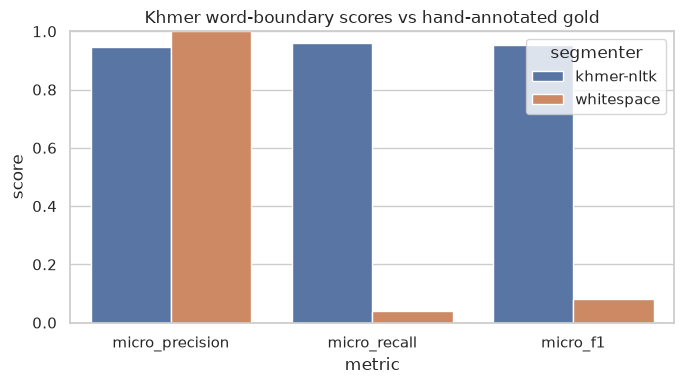

In [33]:
gold_path = BASE_DIR / "segmentation_gold.csv"
if not gold_path.exists():
    pd.DataFrame([
        ("ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។", "ប្រាសាទ អង្គរវត្ត គឺ ជា ប្រាសាទ ហិណ្ឌូ ដ៏ ធំ មួយ នៅ ខេត្ត សៀមរាប ។"),
        ("បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។", "បឹង ទន្លេសាប ជា បឹង ទឹកសាប ដ៏ ធំ នៅ កម្ពុជា និង មាន សារៈសំខាន់ ចំពោះ ជីវភាព ប្រជាជន ។"),
        ("ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។", "ព្រះរាជាណាចក្រ កម្ពុជា មាន រាជធានី ភ្នំពេញ ។"),
        ("បច្ចេកវិទ្យាកុំព្យូទ័រ និងបណ្ដាញអ៊ីនធឺណិតជួយដល់ការអប់រំ។", "បច្ចេកវិទ្យា កុំព្យូទ័រ និង បណ្ដាញ អ៊ីនធឺណិត ជួយ ដល់ ការ អប់រំ ។"),
        ("រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។", "រូបភាព បង្ហាញ ពី ផ្ទះ ឈើ បុរាណ នៅ ប្រទេស កម្ពុជា ។"),
        ("អង្គការសហប្រជាជាតិមានតួនាទីក្នុងកិច្ចសហប្រតិបត្តិការអន្តរជាតិ។", "អង្គការ សហប្រជាជាតិ មាន តួនាទី ក្នុង កិច្ចសហប្រតិបត្តិការ អន្តរជាតិ ។"),
        ("ការសិក្សាបញ្ញាសិប្បនិម្មិត", "ការ សិក្សា បញ្ញាសិប្បនិម្មិត"),
        ("ប្រាសាទអង្គរវត្តនៅឯណា?", "ប្រាសាទ អង្គរវត្ត នៅ ឯណា ?"),
        ("តើរាជធានីកម្ពុជាឈ្មោះអ្វី?", "តើ រាជធានី កម្ពុជា ឈ្មោះ អ្វី ?"),
        ("វិធីសាស្ត្រស្វែងរកឯកសារតាមន័យ", "វិធីសាស្ត្រ ស្វែងរក ឯកសារ តាម ន័យ"),
    ], columns=["text", "gold_segmented"]).to_csv(gold_path, index=False)

gold_df = pd.read_csv(gold_path).fillna("")
for r in gold_df.itertuples():
    assert r.text.replace(" ", "") == r.gold_segmented.replace(" ", ""), f"Gold tokens do not match text: {r.text}"

def boundary_positions(segmented_text):
    # Boundary = character offset (spaces removed) after each token, excluding the end of the string.
    tokens = [t for t in str(segmented_text).split() if t]
    positions, offset = set(), 0
    for tok in tokens[:-1]:
        offset += len(tok)
        positions.add(offset)
    return positions

def segmentation_boundary_metrics(gold, pred):
    g, p = boundary_positions(gold), boundary_positions(pred)
    tp = len(g & p)
    precision = tp / len(p) if p else (1.0 if not g else 0.0)
    recall = tp / len(g) if g else (1.0 if not p else 0.0)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"precision": precision, "recall": recall, "f1": f1,
            "gold_boundaries": len(g), "pred_boundaries": len(p)}

seg_rows = []
for name, fn in SEGMENTERS.items():
    for r in gold_df.itertuples():
        pred = fn(r.text)
        seg_rows.append({"segmenter": name, "text": r.text, "pred": pred, "gold": r.gold_segmented,
                         **segmentation_boundary_metrics(r.gold_segmented, pred)})
seg_eval = pd.DataFrame(seg_rows)

# Micro-averaged boundary scores (pooled over all sentences)
seg_summary = []
for name, g in seg_eval.groupby("segmenter"):
    tp = sum(len(boundary_positions(a) & boundary_positions(b)) for a, b in zip(g.gold, g.pred))
    P, G = g.pred_boundaries.sum(), g.gold_boundaries.sum()
    prec, rec = tp / P if P else 0.0, tp / G if G else 0.0
    seg_summary.append({"segmenter": name, "micro_precision": prec, "micro_recall": rec,
                        "micro_f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
                        "macro_f1": g.f1.mean()})
seg_summary = pd.DataFrame(seg_summary)
display(seg_summary.round(3))
display(seg_eval.loc[seg_eval.segmenter == PRIMARY_SEGMENTER, ["text", "pred", "gold", "f1"]].round(3))

seg_plot = seg_summary.melt(id_vars="segmenter", value_vars=["micro_precision", "micro_recall", "micro_f1"],
                            var_name="metric", value_name="score")
plt.figure(figsize=(7, 4))
sns.barplot(data=seg_plot, x="metric", y="score", hue="segmenter")
plt.title("Khmer word-boundary scores vs hand-annotated gold")
plt.ylim(0, 1); plt.tight_layout(); plt.show()

## 3. Lexical retrieval: TF-IDF and BM25

Two text preparations are compared, each with the **same preparation applied to documents and queries**:
- `normalized` — tokens are whatever whitespace already separates (Khmer phrases stay glued together)
- `segmented` — tokens from the `khmer-nltk` word segmenter

Tokens are lower-cased so English terms match regardless of case, and documents with a zero score (no shared term) are not returned. TF-IDF uses sparse term-weight vectors; BM25 adds term-frequency saturation and document-length normalization.

In [34]:
PUNCT = set("។៕៖ៗ?!.,;:()[]{}\"'“”‘’-–—/")

def lexical_tokens(text):
    return [t.lower() for t in normalize_text(text).split() if t and t not in PUNCT]

def fit_tfidf_retriever(doc_texts):
    vectorizer = TfidfVectorizer(tokenizer=lexical_tokens, token_pattern=None, lowercase=False)
    return vectorizer, vectorizer.fit_transform(doc_texts)

def fit_bm25_retriever(doc_texts):
    return BM25Okapi([lexical_tokens(t) for t in doc_texts])

# Documents with score 0 share no term with the query. They are dropped so that an arbitrary
# tie-break (corpus order) can never be credited as a "hit".
def _ranked_positive(scores, doc_ids, top_k):
    order = [i for i in np.argsort(-scores, kind="stable") if scores[i] > 0][:top_k]
    return [(doc_ids[i], float(scores[i])) for i in order]

def retrieve_tfidf(query, vectorizer, matrix, doc_ids, top_k=10):
    return _ranked_positive(cosine_similarity(vectorizer.transform([query]), matrix).ravel(), doc_ids, top_k)

def retrieve_bm25(query, bm25, doc_ids, top_k=10):
    return _ranked_positive(np.asarray(bm25.get_scores(lexical_tokens(query))), doc_ids, top_k)

doc_ids = docs["doc_id"].tolist()
tfidf_raw, tfidf_raw_matrix = fit_tfidf_retriever(docs["normalized"].tolist())
bm25_raw = fit_bm25_retriever(docs["normalized"].tolist())
tfidf_seg, tfidf_seg_matrix = fit_tfidf_retriever(docs["segmented"].tolist())
bm25_seg = fit_bm25_retriever(docs["segmented"].tolist())

# system name -> (retrieval function(query_text, k), query text column)
LEXICAL_SYSTEMS = {
    "TF-IDF / normalized": (lambda q, k: retrieve_tfidf(q, tfidf_raw, tfidf_raw_matrix, doc_ids, k), "normalized"),
    "BM25 / normalized":   (lambda q, k: retrieve_bm25(q, bm25_raw, doc_ids, k), "normalized"),
    "TF-IDF / segmented":  (lambda q, k: retrieve_tfidf(q, tfidf_seg, tfidf_seg_matrix, doc_ids, k), "segmented"),
    "BM25 / segmented":    (lambda q, k: retrieve_bm25(q, bm25_seg, doc_ids, k), "segmented"),
}
print("Vocabulary size — normalized:", len(tfidf_raw.vocabulary_), "| segmented:", len(tfidf_seg.vocabulary_))

Vocabulary size — normalized: 66 | segmented: 103


## 4. Retrieval evaluation metrics

- **Recall@K:** fraction of relevant documents retrieved in the first K.
- **Precision@K:** fraction of the first K results that are relevant.
- **MRR:** reciprocal rank of the first relevant result.
- **nDCG@K:** ranking quality with higher reward for relevant items near the top.

These are standard metrics for binary relevance labels. K = 5 throughout.

In [35]:
def parse_relevant(value):
    if isinstance(value, (list, tuple, set)):
        return set(map(str, value))
    return {x.strip() for x in str(value).split(";") if x.strip() and x.strip().lower() != "nan"}

def dcg(rels):
    return sum((2**rel - 1) / math.log2(i + 2) for i, rel in enumerate(rels))

def score_ranking(ranked_ids, relevant_ids, k=10):
    relevant_ids = set(relevant_ids)
    hits = [1 if x in relevant_ids else 0 for x in list(ranked_ids)[:k]]
    recall = sum(hits) / len(relevant_ids) if relevant_ids else np.nan
    precision = sum(hits) / k if k else np.nan
    rr = next((1.0 / rank for rank, hit in enumerate(hits, start=1) if hit), 0.0)
    ideal_hits = min(len(relevant_ids), k)
    idcg = dcg([1] * ideal_hits + [0] * (k - ideal_hits))
    ndcg = dcg(hits) / idcg if idcg else 0.0
    return {"recall": recall, "precision": precision, "mrr": rr, "ndcg": ndcg}

def evaluate_retriever(name, retrieval_fn, text_column, query_df=None, k=TOP_K):
    query_df = queries if query_df is None else query_df
    rows = []
    for r in query_df.itertuples():
        ranked = [x[0] for x in retrieval_fn(getattr(r, text_column), k)]
        rows.append({"system": name, "query_id": r.query_id,
                     **score_ranking(ranked, parse_relevant(r.relevant_doc_ids), k)})
    return pd.DataFrame(rows)

metric_cols = ["recall", "precision", "mrr", "ndcg"]
lexical_results = pd.concat([evaluate_retriever(name, fn, col) for name, (fn, col) in LEXICAL_SYSTEMS.items()],
                            ignore_index=True)
display(lexical_results.groupby("system", sort=False)[metric_cols].mean().round(3))

,recall,precision,mrr,ndcg
system,,,,
TF-IDF / normalized,0.214,0.057,0.286,0.230
BM25 / normalized,0.214,0.057,0.286,0.230
TF-IDF / segmented,0.643,0.143,0.714,0.659
BM25 / segmented,0.643,0.143,0.714,0.659


## 5. Dense embeddings: EmbeddingGemma 2 and Qwen3-VL-Embedding-2B

Both models are loaded through their official SentenceTransformers interface with the prompts from their model cards:

| Model | Query prompt | Document prompt | Dim | Precision / device |
|---|---|---|---|---|
| EmbeddingGemma 2 (`google/embeddinggemma-2`) | `SearchQuery` → `task: search result \| query: ` | `Document` → `title: none \| text: ` | 768 | float32 (the card forbids float16), audio encoder disabled |
| Qwen3-VL-Embedding-2B (`Qwen/Qwen3-VL-Embedding-2B`) | `Retrieve relevant documents for the user's query.` | default `Represent the user's input.` | 2048 | bfloat16; GPU if it fits, otherwise CPU |

To fit a laptop, each model is **loaded, used for every experiment (normalized text, segmented text, images, latency), then freed** before the next model loads. The cells after that only score the stored vectors.

**Each model has its own vector space.** Never compare a query from one model against document vectors from another model.

In [36]:
from sentence_transformers import SentenceTransformer

DENSE_MODELS = {
    "EmbeddingGemma2": {
        "model_id": "google/embeddinggemma-2",
        "dtype": torch.float32,                   # float16 produces NaNs per the model card
        "config_kwargs": {"audio_config": None},   # text + image only: smaller footprint
        "approx_gib": 1.8,
        "query_kwargs": {"prompt_name": "SearchQuery"},
        "doc_kwargs": {"prompt_name": "Document"},
        "image_query_kwargs": {"prompt_name": "SearchQuery"},
        "image_kwargs": {},
    },
    "Qwen3-VL-Embedding-2B": {
        "model_id": "Qwen/Qwen3-VL-Embedding-2B",
        "dtype": torch.bfloat16,
        "config_kwargs": {},
        "approx_gib": 4.6,
        "query_kwargs": {"prompt": "Retrieve relevant documents for the user's query."},
        "doc_kwargs": {},                          # model default: "Represent the user's input."
        "image_query_kwargs": {"prompt": "Retrieve images that match the user's description."},
        "image_kwargs": {},
    },
}

def pick_device(approx_gib):
    if torch.cuda.is_available():
        free, _ = torch.cuda.mem_get_info()
        if free / 2**30 > approx_gib + 0.6:   # head-room for activations
            return "cuda"
    return "cpu"

def load_dense_model(name):
    spec = DENSE_MODELS[name]
    device = pick_device(spec["approx_gib"])
    dtype = spec["dtype"]
    if device == "cpu" and dtype == torch.float16:
        dtype = torch.float32
    t0 = time.perf_counter()
    model = SentenceTransformer(spec["model_id"], device=device, trust_remote_code=True,
                                model_kwargs={"dtype": dtype}, config_kwargs=spec["config_kwargs"])
    model.eval()
    print(f"Loaded {name} on {device} ({dtype}) in {time.perf_counter() - t0:.1f}s")
    return model, device, dtype

def free_dense_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def encode(model, inputs, batch_size=4, **kwargs):
    with torch.inference_mode():
        vecs = model.encode(inputs, batch_size=batch_size, convert_to_numpy=True,
                            normalize_embeddings=True, show_progress_bar=False, **kwargs)
    vecs = np.asarray(vecs, dtype=np.float32)
    assert np.isfinite(vecs).all(), "Embedding contains NaN/inf"
    return vecs

# Media manifest for the multimodal experiment (local images next to the notebook)
media_df = pd.read_csv(BASE_DIR / "media.csv").fillna("")
assert {"item_id", "caption", "image_path"}.issubset(media_df.columns)
media_df["image_abspath"] = media_df["image_path"].map(lambda p: str((BASE_DIR / p).resolve()))
missing_images = [p for p in media_df.image_abspath if not Path(p).exists()]
assert not missing_images, f"Missing image files: {missing_images}"
media_images = [Image.open(p).convert("RGB") for p in media_df.image_abspath]
print("Media items:", len(media_df))
display(media_df[["item_id", "caption", "image_path"]])

Media items: 5


,item_id,caption,image_path
0,IMG001,A tabby cat looking at the camera with one paw stretched toward the lens indoors.,assets/image1.jpg
1,IMG002,A white dog with black patches around its eyes and its pink tongue out.,assets/image2.jpg
2,IMG003,A cow wearing sunglasses against a plain blue background.,assets/image3.jpg
3,IMG004,Two close-up portraits of buffalo: a brown bison on the left and a black buffalo with a bird on its head on the right.,assets/image4.jpg
4,IMG005,A lion with a thick golden mane on a white background.,assets/image5.jpg


### 5A. Encode everything with each model (one model in memory at a time)

For every model this cell encodes: normalized queries/documents, segmented queries/documents, image captions (as queries and as documents), and the images themselves. It also measures single-query latency (encode + cosine search). Any loading or encoding error stops the notebook so problems are never silently skipped.

In [37]:
dense_doc_vectors, dense_query_vectors = {}, {}
dense_doc_vectors_seg, dense_query_vectors_seg = {}, {}
media_vectors = {}       # model -> {"caption_query", "caption_doc", "image"}
dense_runtime = []       # model load / encode stats

for name, spec in DENSE_MODELS.items():
    model, device, dtype = load_dense_model(name)
    t0 = time.perf_counter()

    dense_query_vectors[name] = encode(model, queries["normalized"].tolist(), **spec["query_kwargs"])
    dense_doc_vectors[name] = encode(model, docs["normalized"].tolist(), **spec["doc_kwargs"])
    dense_query_vectors_seg[name] = encode(model, queries["segmented"].tolist(), **spec["query_kwargs"])
    dense_doc_vectors_seg[name] = encode(model, docs["segmented"].tolist(), **spec["doc_kwargs"])
    text_encode_s = time.perf_counter() - t0

    t1 = time.perf_counter()
    media_vectors[name] = {
        "caption_query": encode(model, media_df["caption"].tolist(), **spec["image_query_kwargs"]),
        "caption_doc": encode(model, media_df["caption"].tolist(), **spec["doc_kwargs"]),
        "image": encode(model, media_images, batch_size=1, **spec["image_kwargs"]),
    }
    image_encode_s = time.perf_counter() - t1

    # Single-query latency: encode one query, then cosine search over the document vectors.
    samples = []
    for q in queries["normalized"].tolist():
        ts = time.perf_counter()
        qv = encode(model, [q], batch_size=1, **spec["query_kwargs"])
        _ = cosine_similarity(qv, dense_doc_vectors[name]).ravel()
        samples.append((time.perf_counter() - ts) * 1000)

    dense_runtime.append({
        "model": name, "device": device, "dtype": str(dtype).replace("torch.", ""),
        "dimensions": dense_doc_vectors[name].shape[1],
        "text_encode_s": round(text_encode_s, 2), "image_encode_s": round(image_encode_s, 2),
        "ms_per_query": float(np.median(samples)),
        "peak_gpu_GiB": round(torch.cuda.max_memory_allocated() / 2**30, 2) if device == "cuda" else 0.0,
        "process_rss_GiB": round(psutil.Process().memory_info().rss / 2**30, 2),
    })
    print(name, "| docs", dense_doc_vectors[name].shape, "| queries", dense_query_vectors[name].shape,
          "| images", media_vectors[name]["image"].shape)
    free_dense_model(model)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

dense_runtime_df = pd.DataFrame(dense_runtime)
display(dense_runtime_df)

Loading weights: 100%|██████████| 624/624 [00:01<00:00, 524.77it/s]


Loaded EmbeddingGemma2 on cuda (torch.float32) in 11.7s
EmbeddingGemma2 | docs (10, 768) | queries (7, 768) | images (5, 768)


Loading weights: 100%|██████████| 625/625 [00:00<00:00, 7252.87it/s]


Loaded Qwen3-VL-Embedding-2B on cpu (torch.bfloat16) in 2.8s
Qwen3-VL-Embedding-2B | docs (10, 2048) | queries (7, 2048) | images (5, 2048)


,model,device,dtype,dimensions,text_encode_s,image_encode_s,ms_per_query,peak_gpu_GiB,process_rss_GiB
0,EmbeddingGemma2,cuda,float32,768,0.59,4.46,39.493422,1.78,4.71
1,Qwen3-VL-Embedding-2B,cpu,bfloat16,2048,143.84,97.72,1439.778421,0.00,5.56


### 5B. Dense retrieval on normalized text

In [38]:
def retrieve_dense(query_vector, doc_vectors, doc_ids, top_k=10):
    scores = cosine_similarity(np.asarray(query_vector).reshape(1, -1), np.asarray(doc_vectors)).ravel()
    order = np.argsort(-scores, kind="stable")[:top_k]
    return [(doc_ids[i], float(scores[i])) for i in order]

def evaluate_dense(system_name, qvecs, dvecs, k=TOP_K):
    rows = []
    for i, qrow in enumerate(queries.itertuples()):
        ranked = [x[0] for x in retrieve_dense(qvecs[i], dvecs, doc_ids, k)]
        rows.append({"system": system_name, "query_id": qrow.query_id,
                     **score_ranking(ranked, parse_relevant(qrow.relevant_doc_ids), k)})
    return pd.DataFrame(rows)

dense_results = pd.concat([evaluate_dense(f"{m} / normalized", dense_query_vectors[m], dense_doc_vectors[m])
                           for m in DENSE_MODELS], ignore_index=True)
all_results = pd.concat([lexical_results, dense_results], ignore_index=True)
display(dense_results.groupby("system", sort=False)[metric_cols].mean().round(3))

,recall,precision,mrr,ndcg
system,,,,
EmbeddingGemma2 / normalized,1.0,0.286,1.000,0.979
Qwen3-VL-Embedding-2B / normalized,1.0,0.286,0.929,0.940


### 5C. Segmented-input dense comparison

Tests whether Khmer word segmentation helps or hurts each embedding model. Same corpus and labels; only the text preparation changes.

In [39]:
segmented_dense_results = pd.concat(
    [evaluate_dense(f"{m} / segmented", dense_query_vectors_seg[m], dense_doc_vectors_seg[m]) for m in DENSE_MODELS],
    ignore_index=True)
all_results = pd.concat([all_results, segmented_dense_results], ignore_index=True)

seg_vs_raw = (pd.concat([dense_results, segmented_dense_results])
              .assign(model=lambda d: d.system.str.split(" / ").str[0],
                      text=lambda d: d.system.str.split(" / ").str[1])
              .groupby(["model", "text"])[metric_cols].mean().round(3))
display(seg_vs_raw)

recall  precision    mrr   ndcg
model                 text                                       
EmbeddingGemma2       normalized     1.0      0.286  1.000  0.979
                      segmented      1.0      0.286  1.000  0.995
Qwen3-VL-Embedding-2B normalized     1.0      0.286  0.929  0.940
                      segmented      1.0      0.286  1.000  0.995

## 6. Hybrid retrieval with Reciprocal Rank Fusion (RRF)

RRF combines rankings without requiring comparable raw score scales:

$$RRF(d)=\sum_{r \in systems}\frac{1}{k_0 + rank_r(d)}$$

`k0 = 60` is a common starting value; tune it only on a validation set. Three fusions are evaluated: BM25 (segmented) + each dense model, and BM25 (segmented) + both dense models.

In [40]:
def rrf_fuse(rankings, k0=60, top_k=10):
    scores = defaultdict(float)
    for ranked_ids in rankings:
        for rank, doc_id in enumerate(ranked_ids, start=1):
            scores[doc_id] += 1.0 / (k0 + rank)
    return sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top_k]

N = len(doc_ids)
fusions = {f"Hybrid RRF (BM25-seg + {m})": [m] for m in DENSE_MODELS}
fusions["Hybrid RRF (BM25-seg + all dense)"] = list(DENSE_MODELS)

hybrid_rows = []
for system, models in fusions.items():
    for qi, qrow in enumerate(queries.itertuples()):
        rankings = [[x[0] for x in retrieve_bm25(qrow.segmented, bm25_seg, doc_ids, N)]]
        rankings += [[x[0] for x in retrieve_dense(dense_query_vectors[m][qi], dense_doc_vectors[m], doc_ids, N)]
                     for m in models]
        fused = [x[0] for x in rrf_fuse(rankings, top_k=TOP_K)]
        hybrid_rows.append({"system": system, "query_id": qrow.query_id,
                            **score_ranking(fused, parse_relevant(qrow.relevant_doc_ids), TOP_K)})
hybrid_results = pd.DataFrame(hybrid_rows)
all_results = pd.concat([all_results, hybrid_results], ignore_index=True)
display(hybrid_results.groupby("system", sort=False)[metric_cols].mean().round(3))

,recall,precision,mrr,ndcg
system,,,,
Hybrid RRF (BM25-seg + EmbeddingGemma2),1.0,0.286,1.0,0.979
Hybrid RRF (BM25-seg + Qwen3-VL-Embedding-2B),1.0,0.286,1.0,0.992
Hybrid RRF (BM25-seg + all dense),1.0,0.286,1.0,0.987


## 7. Multimodal retrieval: text → image and image → text

Uses `media.csv` (5 local images with gold English captions). Item *i*'s caption is the only relevant match for image *i*.

- **text → image:** each caption (with the model's retrieval query prompt) searches the image vectors.
- **image → text:** each image searches the caption vectors (document prompt).

Images are passed to SentenceTransformers as PIL images, without text prompts for EmbeddingGemma 2 (per its card) and with Qwen's default system instruction. Video and audio are not evaluated because no local video/audio files are provided; Qwen3-VL-Embedding does not support audio.

recall@1  mrr  ndcg
model                 direction                      
EmbeddingGemma2       image→text       1.0  1.0   1.0
                      text→image       1.0  1.0   1.0
Qwen3-VL-Embedding-2B image→text       1.0  1.0   1.0
                      text→image       1.0  1.0   1.0

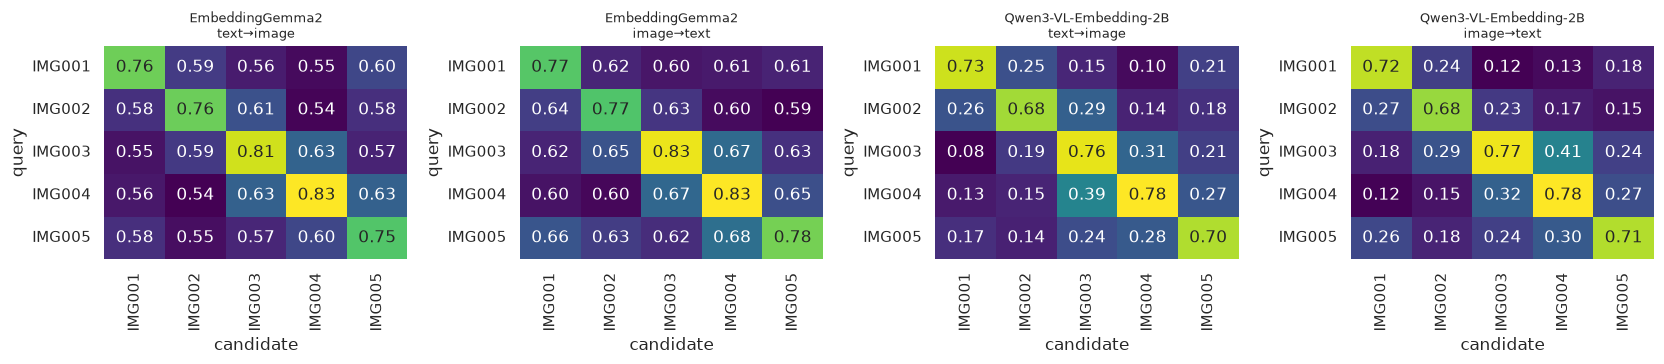

In [41]:
item_ids = media_df["item_id"].astype(str).tolist()
mm_rows, mm_sims = [], {}
for m in DENSE_MODELS:
    mv = media_vectors[m]
    for direction, Q, D in [("text→image", mv["caption_query"], mv["image"]),
                            ("image→text", mv["image"], mv["caption_doc"])]:
        sim = cosine_similarity(Q, D)
        mm_sims[(m, direction)] = sim
        for i in range(len(item_ids)):
            ranked = [item_ids[j] for j in np.argsort(-sim[i], kind="stable")]
            s = score_ranking(ranked, {item_ids[i]}, k=len(item_ids))
            mm_rows.append({"model": m, "direction": direction, "item_id": item_ids[i],
                            "recall@1": float(ranked[0] == item_ids[i]), "mrr": s["mrr"], "ndcg": s["ndcg"]})
multimodal_results = pd.DataFrame(mm_rows)
display(multimodal_results.groupby(["model", "direction"])[["recall@1", "mrr", "ndcg"]].mean().round(3))

fig, axes = plt.subplots(1, len(mm_sims), figsize=(4.2 * len(mm_sims), 3.8))
for ax, ((m, direction), sim) in zip(np.atleast_1d(axes), mm_sims.items()):
    sns.heatmap(sim, annot=True, fmt=".2f", cmap="viridis", ax=ax, cbar=False,
                xticklabels=item_ids, yticklabels=item_ids)
    ax.set_title(f"{m}\n{direction}", fontsize=9)
    ax.set_xlabel("candidate"); ax.set_ylabel("query")
plt.tight_layout(); plt.show()

### 7B. Matryoshka dimension experiment

EmbeddingGemma 2 supports truncation to 512 / 256 / 128 dimensions; Qwen3-VL-Embedding supports user-defined sizes from 64 to 2048 (MRL). Vectors are re-normalized after truncation; queries and documents always share a dimension.

,model,dimensions,recall,precision,mrr,ndcg
0,EmbeddingGemma2,128,0.952,0.257,1.000,0.966
1,EmbeddingGemma2,256,0.952,0.257,1.000,0.950
2,EmbeddingGemma2,512,1.000,0.286,1.000,0.987
3,EmbeddingGemma2,768,1.000,0.286,1.000,0.979
4,Qwen3-VL-Embedding-2B,64,1.000,0.286,0.929,0.934
5,Qwen3-VL-Embedding-2B,128,1.000,0.286,1.000,1.000
6,Qwen3-VL-Embedding-2B,256,1.000,0.286,0.929,0.943
7,Qwen3-VL-Embedding-2B,512,1.000,0.286,0.929,0.940
8,Qwen3-VL-Embedding-2B,1024,1.000,0.286,1.000,0.992
9,Qwen3-VL-Embedding-2B,2048,1.000,0.286,0.929,0.940


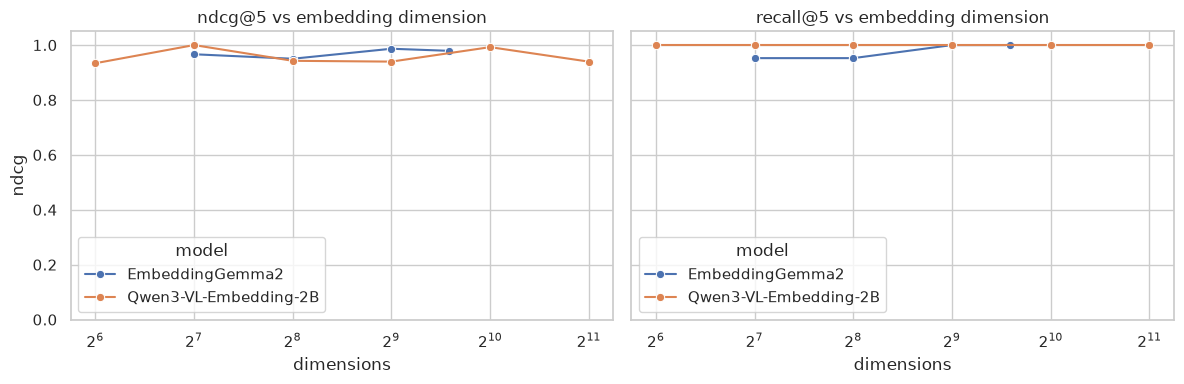

In [42]:
MRL_DIMS = {"EmbeddingGemma2": [128, 256, 512, 768],
            "Qwen3-VL-Embedding-2B": [64, 128, 256, 512, 1024, 2048]}

def l2norm(x):
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-12, None)

dim_rows = []
for m, dims in MRL_DIMS.items():
    full_d, full_q = dense_doc_vectors[m], dense_query_vectors[m]
    assert full_d.shape[1] == max(dims), f"{m}: expected {max(dims)}D, got {full_d.shape[1]}"
    for dim in dims:
        res = evaluate_dense(m, l2norm(full_q[:, :dim]), l2norm(full_d[:, :dim]))
        dim_rows.append({"model": m, "dimensions": dim, **res[metric_cols].mean().to_dict()})
dim_results = pd.DataFrame(dim_rows)
display(dim_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric in zip(axes, ["ndcg", "recall"]):
    sns.lineplot(data=dim_results, x="dimensions", y=metric, hue="model", marker="o", ax=ax)
    ax.set_xscale("log", base=2); ax.set_ylim(0, 1.05); ax.set_title(f"{metric}@{TOP_K} vs embedding dimension")
plt.tight_layout(); plt.show()

## 8. Embedding dimension and vector storage

Storage estimate for dense float32 vectors:

$$storage \approx N_{documents} \times dimensions \times 4\ bytes$$

This excludes vector-index overhead, metadata, replicas, and compression.

,dimensions,storage_MB_this_corpus,storage_GB_for_1M
0,64,0.0024,0.2384
1,128,0.0049,0.4768
2,256,0.0098,0.9537
3,384,0.0146,1.4305
4,512,0.0195,1.9073
5,768,0.0293,2.8610
6,1024,0.0391,3.8147
7,1536,0.0586,5.7220
8,2048,0.0781,7.6294
9,3072,0.1172,11.4441


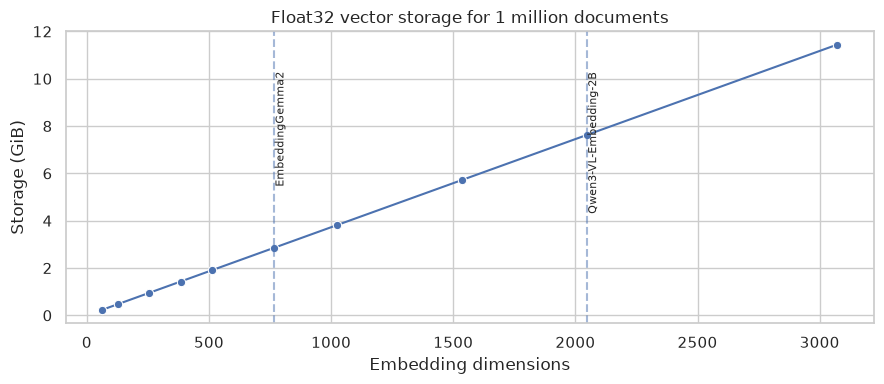

In [43]:
def vector_storage_mb(n_vectors, dimensions, bytes_per_value=4):
    return n_vectors * dimensions * bytes_per_value / (1024**2)

dimension_options = [64, 128, 256, 384, 512, 768, 1024, 1536, 2048, 3072]
storage_df = pd.DataFrame({
    "dimensions": dimension_options,
    "storage_MB_this_corpus": [vector_storage_mb(len(docs), d) for d in dimension_options],
    "storage_GB_for_1M": [vector_storage_mb(1_000_000, d) / 1024 for d in dimension_options],
})
display(storage_df.round(4))
plt.figure(figsize=(9, 4))
sns.lineplot(data=storage_df, x="dimensions", y="storage_GB_for_1M", marker="o")
for m, spec_dim in [("EmbeddingGemma2", 768), ("Qwen3-VL-Embedding-2B", 2048)]:
    plt.axvline(spec_dim, ls="--", alpha=.5)
    plt.text(spec_dim, storage_df.storage_GB_for_1M.max() * .9, " " + m, rotation=90, va="top", fontsize=8)
plt.title("Float32 vector storage for 1 million documents")
plt.ylabel("Storage (GiB)"); plt.xlabel("Embedding dimensions")
plt.tight_layout(); plt.show()

## 9. Benchmark visualization

All plots below come from the same query-level evaluation table. With a real dataset, compare systems by mean scores **and** per-query variance.

recall        precision         \
                                                mean    std      mean    std   
system                                                                         
TF-IDF / normalized                            0.214  0.393     0.057  0.098   
BM25 / normalized                              0.214  0.393     0.057  0.098   
TF-IDF / segmented                             0.643  0.476     0.143  0.098   
BM25 / segmented                               0.643  0.476     0.143  0.098   
EmbeddingGemma2 / normalized                   1.000  0.000     0.286  0.157   
Qwen3-VL-Embedding-2B / normalized             1.000  0.000     0.286  0.157   
EmbeddingGemma2 / segmented                    1.000  0.000     0.286  0.157   
Qwen3-VL-Embedding-2B / segmented              1.000  0.000     0.286  0.157   
Hybrid RRF (BM25-seg + EmbeddingGemma2)        1.000  0.000     0.286  0.157   
Hybrid RRF (BM25-seg + Qwen3-VL-Embedding-2B)  1.000  0.000     0.286  0.157   
Hybrid RRF (BM25-seg + all dense)              1.000  0.000     0.286  0.157   

                                                 mrr          ndcg         
                                                mean    std   mean    std  
system                                                                     
TF-IDF / normalized                            0.286  0.488  0.230  0.409  
BM25 / normalized                              0.286  0.488  0.230  0.409  
TF-IDF / segmented                             0.714  0.488  0.659  0.472  
BM25 / segmented                               0.714  0.488  0.659  0.472  
EmbeddingGemma2 / normalized                   1.000  0.000  0.979  0.056  
Qwen3-VL-Embedding-2B / normalized             0.929  0.189  0.940  0.138  
EmbeddingGemma2 / segmented                    1.000  0.000  0.995  0.012  
Qwen3-VL-Embedding-2B / segmented              1.000  0.000  0.995  0.012  
Hybrid RRF (BM25-seg + EmbeddingGemma2)        1.000  0.000  0.979  0.056  
Hybrid RRF (BM25-seg + Qwen3-VL-Embedding-2B)  1.000  0.000  0.992  0.020  
Hybrid RRF (BM25-seg + all dense)              1.000  0.000  0.987  0.036

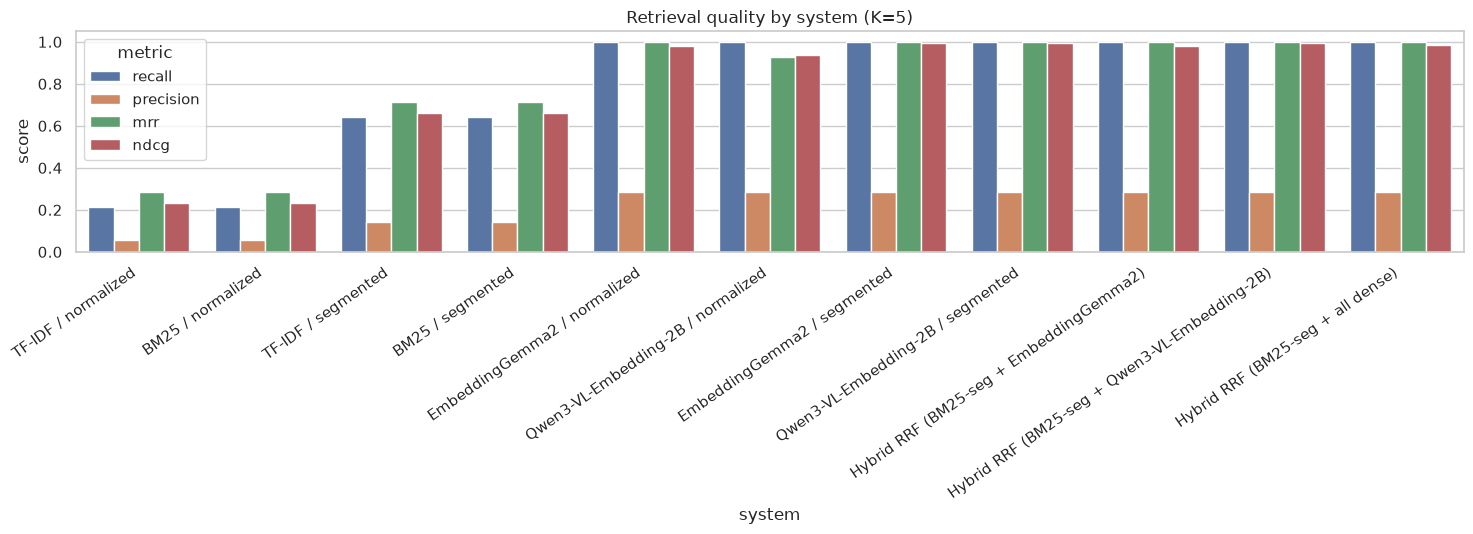

In [44]:
system_order = list(dict.fromkeys(all_results["system"]))
summary = all_results.groupby("system", sort=False)[metric_cols].agg(["mean", "std"]).round(3)
display(summary)

plot_df = (all_results.groupby("system", sort=False)[metric_cols].mean().reset_index()
           .melt(id_vars="system", var_name="metric", value_name="score"))
plt.figure(figsize=(15, 5.5))
sns.barplot(data=plot_df, x="system", y="score", hue="metric", order=system_order)
plt.title(f"Retrieval quality by system (K={TOP_K})")
plt.xticks(rotation=35, ha="right"); plt.ylim(0, 1.05)
plt.tight_layout(); plt.show()

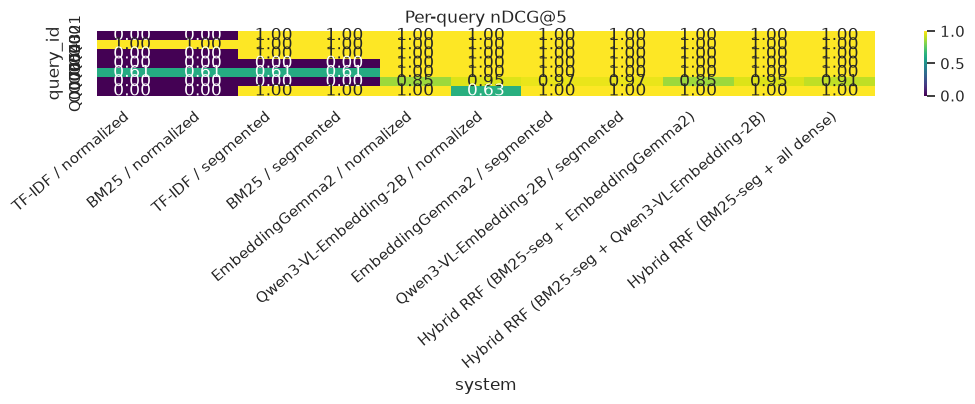

In [45]:
# Per-query heatmap: which queries each method struggles with.
pivot = all_results.pivot_table(index="query_id", columns="system", values="ndcg", sort=False)[system_order]
plt.figure(figsize=(max(9, 1.0 * len(pivot.columns)), max(4, .6 * len(pivot.index))))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title(f"Per-query nDCG@{TOP_K}")
plt.xticks(rotation=40, ha="right")
plt.tight_layout(); plt.show()

,system,family,ms_per_query
0,TF-IDF / normalized,lexical,0.786
1,BM25 / normalized,lexical,0.037
2,TF-IDF / segmented,lexical,0.780
3,BM25 / segmented,lexical,0.062
4,EmbeddingGemma2 / normalized (cuda),dense,39.493
5,Qwen3-VL-Embedding-2B / normalized (cpu),dense,1439.778


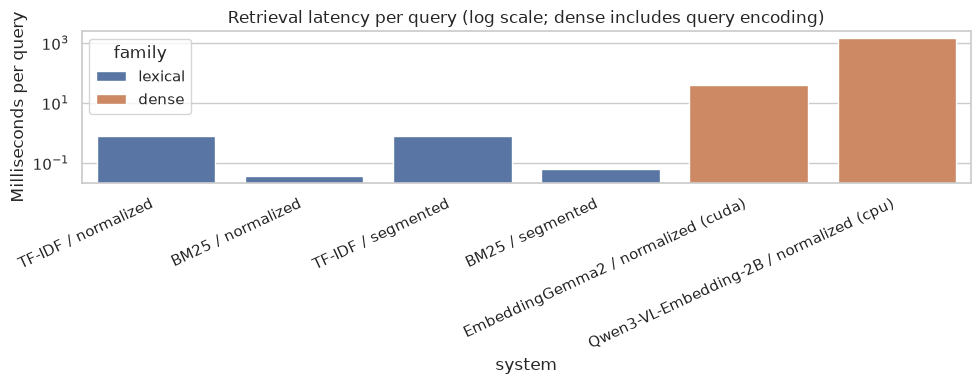

In [46]:
# Latency: lexical systems (median over repeats) + dense single-query latency measured in section 5A.
def time_retriever(fn, qlist, repeats=5):
    samples = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        for q in qlist:
            fn(q, TOP_K)
        samples.append((time.perf_counter() - t0) / max(1, len(qlist)) * 1000)
    return float(np.median(samples))

latency_rows = [{"system": name, "family": "lexical", "ms_per_query": time_retriever(fn, queries[col].tolist())}
                for name, (fn, col) in LEXICAL_SYSTEMS.items()]
latency_rows += [{"system": f"{r.model} / normalized ({r.device})", "family": "dense", "ms_per_query": r.ms_per_query}
                 for r in dense_runtime_df.itertuples()]
latency_df = pd.DataFrame(latency_rows)
display(latency_df.round(3))

plt.figure(figsize=(10, 4))
sns.barplot(data=latency_df, x="system", y="ms_per_query", hue="family")
plt.yscale("log")
plt.title("Retrieval latency per query (log scale; dense includes query encoding)")
plt.ylabel("Milliseconds per query"); plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

## 10. Error analysis: inspect failed queries

Ranked results per query, and the queries where no relevant document appears in the top five. Useful for diagnosing Khmer word-boundary errors, spelling variants, cross-language mismatch, semantic drift, and incomplete relevance judgments.

In [47]:
def show_query_results(query_id, system="BM25 / segmented", top_k=TOP_K):
    qi = int(queries.index[queries.query_id == str(query_id)][0])
    qrow = queries.loc[qi]
    relevant = parse_relevant(qrow["relevant_doc_ids"])
    if system in LEXICAL_SYSTEMS:
        fn, col = LEXICAL_SYSTEMS[system]
        ranked = fn(qrow[col], top_k)
    elif system.endswith(" / segmented") and system.split(" / ")[0] in DENSE_MODELS:
        m = system.split(" / ")[0]
        ranked = retrieve_dense(dense_query_vectors_seg[m][qi], dense_doc_vectors_seg[m], doc_ids, top_k)
    elif system.split(" / ")[0] in DENSE_MODELS:
        m = system.split(" / ")[0]
        ranked = retrieve_dense(dense_query_vectors[m][qi], dense_doc_vectors[m], doc_ids, top_k)
    else:
        raise ValueError("Unknown system: " + system)
    doc_text = docs.set_index("doc_id")["text"]
    return pd.DataFrame([{"rank": rank, "doc_id": did, "score": round(score, 4), "relevant": did in relevant,
                          "text": doc_text[did]} for rank, (did, score) in enumerate(ranked, start=1)])

first_q = queries.iloc[0]
print(f"Query {first_q.query_id}: {first_q.query}  | relevant: {first_q.relevant_doc_ids}")
for system in ["BM25 / normalized", "BM25 / segmented"] + [f"{m} / normalized" for m in DENSE_MODELS]:
    print("\n" + system)
    display(show_query_results(first_q.query_id, system))

failures = (all_results[all_results["recall"] == 0]
            .merge(queries[["query_id", "query", "relevant_doc_ids"]], on="query_id")
            [["system", "query_id", "query", "relevant_doc_ids"]])
print(f"\nQuery/system pairs with no relevant document in the top {TOP_K}: {len(failures)}")
display(failures)

Query Q001: ប្រាសាទអង្គរវត្តនៅឯណា?  | relevant: D001

BM25 / normalized


""



BM25 / segmented


,rank,doc_id,score,relevant,text
0,1,D001,4.3557,True,ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។ Angkor Wat is a famous temple in Cambodia.
1,2,D009,0.8694,False,រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។
2,3,D003,0.6531,False,បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។



EmbeddingGemma2 / normalized


,rank,doc_id,score,relevant,text
0,1,D001,0.8259,True,ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។ Angkor Wat is a famous temple in Cambodia.
1,2,D009,0.6774,False,រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។
2,3,D006,0.6570,False,ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។ Phnom Penh is the capital of Cambodia.
3,4,D008,0.6423,False,"A document about Cambodian traditional wooden houses, architecture, roofs, columns and construction materials."
4,5,D004,0.6422,False,អង្គការសហប្រជាជាតិ (United Nations) មានតួនាទីក្នុងកិច្ចសហប្រតិបត្តិការអន្តរជាតិ។



Qwen3-VL-Embedding-2B / normalized


,rank,doc_id,score,relevant,text
0,1,D001,0.7729,True,ប្រាសាទអង្គរវត្ត គឺជាប្រាសាទហិណ្ឌូដ៏ធំមួយនៅខេត្តសៀមរាប។ Angkor Wat is a famous temple in Cambodia.
1,2,D009,0.5282,False,រូបភាពបង្ហាញពីផ្ទះឈើបុរាណនៅប្រទេសកម្ពុជា។
2,3,D006,0.4918,False,ព្រះរាជាណាចក្រកម្ពុជាមានរាជធានីភ្នំពេញ។ Phnom Penh is the capital of Cambodia.
3,4,D008,0.4152,False,"A document about Cambodian traditional wooden houses, architecture, roofs, columns and construction materials."
4,5,D003,0.4077,False,បឹងទន្លេសាបជាបឹងទឹកសាបដ៏ធំនៅកម្ពុជា និងមានសារៈសំខាន់ចំពោះជីវភាពប្រជាជន។



Query/system pairs with no relevant document in the top 5: 14


,system,query_id,query,relevant_doc_ids
0,TF-IDF / normalized,Q001,ប្រាសាទអង្គរវត្តនៅឯណា?,D001
1,TF-IDF / normalized,Q003,តើរាជធានីកម្ពុជាឈ្មោះអ្វី?,D006
2,TF-IDF / normalized,Q004,United Nations,D004
3,TF-IDF / normalized,Q006,វិធីសាស្ត្រស្វែងរកឯកសារតាមន័យ,D002;D005;D010
4,TF-IDF / normalized,Q007,ទន្លេសាប,D003
5,BM25 / normalized,Q001,ប្រាសាទអង្គរវត្តនៅឯណា?,D001
6,BM25 / normalized,Q003,តើរាជធានីកម្ពុជាឈ្មោះអ្វី?,D006
7,BM25 / normalized,Q004,United Nations,D004
8,BM25 / normalized,Q006,វិធីសាស្ត្រស្វែងរកឯកសារតាមន័យ,D002;D005;D010
9,BM25 / normalized,Q007,ទន្លេសាប,D003


## 11. Research checklist and experiment log

Before reporting results:

- [ ] Use a real Khmer corpus, not only the demo corpus.
- [ ] Create human-judged query–document relevance labels.
- [ ] Split queries into development/validation/test sets.
- [x] Record the exact model revision, package versions, and runtime (section 11B).
- [x] Use the official embedding recipe for each model (prompts, pooling, normalization).
- [x] Keep each model's document vectors separate.
- [x] Compare raw-normalized and segmented text with the same preparation for queries and documents.
- [ ] Evaluate segmentation with a **larger** independently annotated gold set.
- [ ] Report confidence intervals or bootstrap variation when the test set is large enough.
- [ ] Do not tune on the final test queries.

### Experiment matrix (all run in this notebook)

| ID | Text preparation | Retrieval |
|---|---|---|
| E1 | Normalized raw Khmer | TF-IDF |
| E2 | Normalized raw Khmer | BM25 |
| E3 | khmer-nltk segmented | TF-IDF |
| E4 | khmer-nltk segmented | BM25 |
| E5 | Raw-normalized | EmbeddingGemma 2 |
| E6 | Segmented | EmbeddingGemma 2 |
| E7 | Raw-normalized | Qwen3-VL-Embedding-2B |
| E8 | Segmented | Qwen3-VL-Embedding-2B |
| E9 | BM25-seg + dense | RRF hybrid |
| E10 | Caption ↔ image | Text→image / image→text |

### Export results

In [48]:
all_results.to_csv(RESULTS_DIR / "query_level_metrics.csv", index=False)
all_results.groupby("system", sort=False)[metric_cols].agg(["mean", "std"]).to_csv(RESULTS_DIR / "system_summary.csv")
seg_summary.to_csv(RESULTS_DIR / "segmentation_summary.csv", index=False)
seg_eval.to_csv(RESULTS_DIR / "segmentation_per_sentence.csv", index=False)
multimodal_results.to_csv(RESULTS_DIR / "multimodal_metrics.csv", index=False)
dim_results.to_csv(RESULTS_DIR / "mrl_dimension_metrics.csv", index=False)
storage_df.to_csv(RESULTS_DIR / "embedding_storage_estimates.csv", index=False)
latency_df.to_csv(RESULTS_DIR / "latency.csv", index=False)
dense_runtime_df.to_csv(RESULTS_DIR / "dense_runtime.csv", index=False)

print("Saved:")
for p in sorted(RESULTS_DIR.glob("*.csv")):
    print("-", p.relative_to(BASE_DIR))

Saved:
- khmerir_results/dense_runtime.csv
- khmerir_results/embedding_storage_estimates.csv
- khmerir_results/latency.csv
- khmerir_results/mrl_dimension_metrics.csv
- khmerir_results/multimodal_metrics.csv
- khmerir_results/query_level_metrics.csv
- khmerir_results/segmentation_per_sentence.csv
- khmerir_results/segmentation_summary.csv
- khmerir_results/system_summary.csv


## 11B. Record exact runtime and model versions

Saved as `khmerir_results/run_info.json` alongside the result CSVs.

In [49]:
import importlib.metadata as im
from huggingface_hub import HfApi, try_to_load_from_cache

packages_to_record = ["torch", "transformers", "sentence-transformers", "huggingface_hub", "scikit-learn",
                      "rank-bm25", "numpy", "pandas", "khmer-nltk", "pillow"]
run_info = {"packages": {}}
for package in packages_to_record:
    try:
        run_info["packages"][package] = im.version(package)
    except im.PackageNotFoundError:
        run_info["packages"][package] = "not installed"

run_info["python"] = sys.version
run_info["platform"] = platform.platform()
run_info["cuda_available"] = torch.cuda.is_available()
run_info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
run_info["data_source"] = DATA_SOURCE
run_info["segmenter"] = PRIMARY_SEGMENTER
run_info["models"] = {}
for m, spec in DENSE_MODELS.items():
    cfg = try_to_load_from_cache(spec["model_id"], "config.json")
    revision = Path(cfg).parent.name if isinstance(cfg, str) else "unknown"
    run_info["models"][m] = {"model_id": spec["model_id"], "revision": revision,
                             **dense_runtime_df.set_index("model").loc[m, ["device", "dtype", "dimensions"]]
                             .astype(str).to_dict()}

(RESULTS_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2, ensure_ascii=False))
print(json.dumps(run_info, indent=2, ensure_ascii=False))

{
  "packages": {
    "torch": "2.15.0",
    "transformers": "5.23.0",
    "sentence-transformers": "6.3.0",
    "huggingface_hub": "2.4.0",
    "scikit-learn": "1.9.1",
    "rank-bm25": "0.2.2",
    "numpy": "2.5.4",
    "pandas": "3.0.6",
    "khmer-nltk": "1.6",
    "pillow": "12.3.0"
  },
  "python": "3.14.10 (main, Nov  4 2026, 18:21:50) [GCC 16.2.1 20260810]",
  "platform": "Linux-7.2.3-arch1-2-x86_64-with-glibc2.44",
  "cuda_available": true,
  "gpu": "NVIDIA GeForce GTX 1650",
  "data_source": "built-in demo corpus",
  "segmenter": "khmer-nltk",
  "models": {
    "EmbeddingGemma2": {
      "model_id": "google/embeddinggemma-2",
      "revision": "f9972ac22e696a105c482202646979e33e4b5a1e",
      "device": "cuda",
      "dtype": "float32",
      "dimensions": "768"
    },
    "Qwen3-VL-Embedding-2B": {
      "model_id": "Qwen/Qwen3-VL-Embedding-2B",
      "revision": "9f2f7e710d6d81056aa5c0a4f04764fec6bb7bda",
      "device": "cpu",
      "dtype": "bfloat16",
      "dimensions": 

## 12. Model-specific references and reproducibility notes

**EmbeddingGemma 2**
- [Official model card](https://ai.google.dev/gemma/docs/embeddinggemma/model_card_2)
- [Official multimodal SentenceTransformers guide](https://ai.google.dev/gemma/docs/embeddinggemma/multimodal-embeddinggemma-with-sentence-transformers)
- [Hugging Face model](https://huggingface.co/google/embeddinggemma-2)

**Qwen3-VL-Embedding-2B**
- [Official Hugging Face model card and SentenceTransformers usage](https://huggingface.co/Qwen/Qwen3-VL-Embedding-2B)
- [Qwen3-VL-Embedding GitHub repository](https://github.com/QwenLM/Qwen3-VL-Embedding)

**Khmer segmentation**
- [khmer-nltk](https://github.com/VietHoang1512/khmer-nltk) (segmenter used here)
- [UnifiedCut paper (Applied Sciences, 2024)](https://www.mdpi.com/2076-3417/14/23/11435)
- [UnifiedCut code/data availability referenced by the paper](https://github.com/xianyt/jontcut)
- [KhPOS corpus and project](https://github.com/ye-kyaw-thu/khPOS)
- [CADT Khmer-NLP-Tools](https://github.com/IDRI-LAB/Khmer-NLP-Tools)

**Lexical retrieval / evaluation**
- [rank-bm25](https://github.com/dorianbrown/rank_bm25)
- [scikit-learn TF-IDF](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction)
- [SentenceTransformers](https://www.sbert.net/)

**Important research cautions**
1. The built-in corpus and the 10-sentence segmentation gold set are smoke tests, not benchmarks.
2. The whitespace segmenter is not a real Khmer segmenter; it is reported only as a baseline.
3. For UnifiedCut, use the paper's implementation and its expected preprocessing; do not label another segmenter as UnifiedCut.
4. `khmer-nltk` is a CRF model trained on its own corpus; its segmentation conventions (e.g. compounds) may differ from your gold standard.
5. Dense models use their SentenceTransformers configs and model-card prompts. EmbeddingGemma 2 runs in float32 (float16 gives NaNs); Qwen runs in bfloat16.
6. Qwen3-VL-Embedding supports text/image/video, not audio. EmbeddingGemma 2 documents text, image, video and audio (audio encoder disabled here to save memory).
7. Each model's embeddings belong to its own vector space. Never mix query and document vectors from different models.
8. Truncated (MRL) vectors must be re-normalized, and queries/documents must share the same dimension.